# Praktikum 2 : FAISS pada data kafe

Exact NN (Flat) indices: [[ 0 20 85]] distances: [[0.0000000e+00 8.3148279e-07 1.7266887e-06]]
IVF+PQ indices: [[ 0 20 85]] distances: [[3.2596290e-09 8.2282349e-07 1.7168932e-06]]
Waktu Exact: 0.0015560000010736985
Waktu IVF+PQ: 0.0007172999994509155


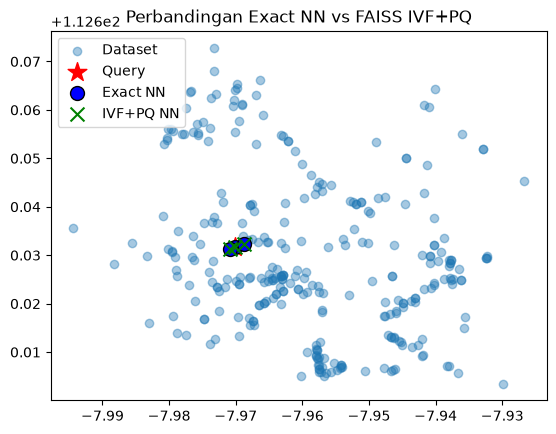

In [1]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

faiss.omp_set_num_threads(4)  # jumlah thread tetap selama percobaan

# 1. Buat dataset 2D sederhana
np.random.seed(42)
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
features = ['latitude', 'longitude', 'rating', 'review_count', 'price_min']
df[features] = df[features].fillna(df[features].mean())
X = df[['latitude', 'longitude']].to_numpy(dtype='float32')
query = X[:1].copy()

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.perf_counter()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.perf_counter()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.perf_counter()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.perf_counter()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
valid_ids = I_ivfpq[0][I_ivfpq[0] >= 0]
plt.scatter(X[valid_ids,0], X[valid_ids,1], c='green', marker='x', s=100, label='IVF+PQ NN')

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

In [2]:
import pandas as pd
from IPython.display import display

def uji_faiss(metric='euclidean', n_points=1000, dimensi=2):
    np.random.seed(42)
    x = np.ascontiguousarray(df[features[:dimensi]].iloc[:n_points], dtype='float32')
    query = x[:1].copy()
    k, nlist, m, nbits = 3, 10, dimensi, 8

    if metric == 'cosine':
        faiss.normalize_L2(x)
        faiss.normalize_L2(query)
        metric_faiss = faiss.METRIC_INNER_PRODUCT
        index_flat = faiss.IndexFlatIP(dimensi)
        quantizer = faiss.IndexFlatIP(dimensi)
    else:
        metric_faiss = faiss.METRIC_L2
        index_flat = faiss.IndexFlatL2(dimensi)
        quantizer = faiss.IndexFlatL2(dimensi)

    index_flat.add(x)
    start = time.perf_counter()
    D_flat, I_flat = index_flat.search(query, k)
    time_flat = (time.perf_counter() - start) * 1000

    index_ivfpq = faiss.IndexIVFPQ(
        quantizer, dimensi, nlist, m, nbits, metric_faiss
    )
    index_ivfpq.cp.seed = 42
    index_ivfpq.pq.cp.seed = 42
    index_ivfpq.nprobe = 1
    index_ivfpq.train(x)
    index_ivfpq.add(x)

    start = time.perf_counter()
    D_ivfpq, I_ivfpq = index_ivfpq.search(query, k)
    time_ivfpq = (time.perf_counter() - start) * 1000

    idx_exact = I_flat[0].tolist()
    idx_ann = I_ivfpq[0].tolist()
    print(f'{metric.upper()} | {n_points:,} data | {dimensi}D')
    print('Exact index:', idx_exact, '| skor:', D_flat[0].tolist())
    print('IVF+PQ index:', idx_ann, '| skor aproksimasi:', D_ivfpq[0].tolist())
    print('-' * 60)

    return {
        'Distance Metrics': metric.capitalize(), 'Jumlah data': n_points,
        'Dimensi': dimensi, 'm': m,
        'Hasil Index terdekat ENN vs ANN': f'{idx_exact}, {idx_ann}',
        'Waktu komputasi ENN vs ANN (ms)': f'{time_flat:.6f}, {time_ivfpq:.6f}',
    }

hasil_faiss = []
for metric in ['euclidean', 'cosine']:
    for n_points in [256, len(df)]:
        for dimensi in [2, 5]:
            hasil_faiss.append(uji_faiss(metric, n_points, dimensi))

tabel_faiss = pd.DataFrame(hasil_faiss)
with pd.option_context('display.max_colwidth', None):
    display(tabel_faiss)

EUCLIDEAN | 256 data | 2D
Exact index: [0, 20, 85] | skor: [0.0, 8.314827937283553e-07, 1.7266886516154045e-06]
IVF+PQ index: [0, 20, 85] | skor aproksimasi: [-8.958159014582634e-08, 8.193892426788807e-07, 1.7325510270893574e-06]
------------------------------------------------------------
EUCLIDEAN | 256 data | 5D
Exact index: [0, 85, 225] | skor: [0.0, 4.0100016593933105, 11.25086784362793]
IVF+PQ index: [0, 85, 225] | skor aproksimasi: [-0.00390625, 4.005859375, 11.2470703125]
------------------------------------------------------------
EUCLIDEAN | 302 data | 2D
Exact index: [0, 20, 85] | skor: [0.0, 8.314827937283553e-07, 1.7266886516154045e-06]
IVF+PQ index: [0, 20, 85] | skor aproksimasi: [2.5902409106492996e-08, 8.007627911865711e-07, 1.717184204608202e-06]
------------------------------------------------------------
EUCLIDEAN | 302 data | 5D
Exact index: [0, 85, 225] | skor: [0.0, 4.0100016593933105, 11.25086784362793]
IVF+PQ index: [0, 85, 225] | skor aproksimasi: [0.0, 4.0117

,Distance Metrics,Jumlah data,Dimensi,m,Hasil Index terdekat ENN vs ANN,Waktu komputasi ENN vs ANN (ms)
0,Euclidean,256,2,2,"[0, 20, 85], [0, 20, 85]","0.055300, 0.108400"
1,Euclidean,256,5,5,"[0, 85, 225], [0, 85, 225]","0.020700, 0.078600"
2,Euclidean,302,2,2,"[0, 20, 85], [0, 20, 85]","0.033100, 0.033400"
3,Euclidean,302,5,5,"[0, 85, 225], [0, 85, 225]","0.020300, 0.036300"
4,Cosine,256,2,2,"[22, 21, 17], [11, 8, 4]","0.032500, 0.080500"
5,Cosine,256,5,5,"[0, 85, 225], [0, 85, 225]","0.024700, 0.044700"
6,Cosine,302,2,2,"[22, 21, 17], [94, 27, 22]","0.019100, 0.030800"
7,Cosine,302,5,5,"[0, 85, 225], [0, 225, 85]","0.028400, 0.074300"
